# HUA: Huawei Cloud 2025 request traces

Platform delay is `totalCost_frontend - runtimeCost`. The first request per `podID` counts as cold.
Every query is memory-bound on the full 944M-row table: the `PRAGMA`s and paths assume a large
server, so adjust them to your machine.

In [7]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.ticker as mtick
from glob import glob
import seaborn as sns
import duckdb
import os
import gc

## Ingest

Builds `2025-public-requests.duckdb` from the CSV parts (944,522,485 rows).

In [1]:
# 2025 public request ingest

from pathlib import Path
import duckdb

# CONFIG
ROOT = Path("huawei-data/2025-public-requests/")   # <-- top-level folder containing region-1..5
DB_PATH = ROOT / "2025-public-requests.duckdb"
TABLE = "requests_latency"

# INGEST
con = duckdb.connect(str(DB_PATH))
con.execute("PRAGMA threads=30")
con.execute("PRAGMA memory_limit='200GB'")

con.execute(f"DROP TABLE IF EXISTS {TABLE}")

# Ingest all CSVs under region-*/R*_*/part-*.csv
con.execute(f"""
    CREATE TABLE {TABLE} AS
    SELECT
        regexp_extract(filename, 'region-\\d+', 0) AS region,
        regexp_extract(filename, 'R\\d+_\\d+_\\d+', 0) AS range_bucket,
        *
    FROM read_csv_auto('{ROOT}/region-*/R*_*/part-*.csv', filename=true)
""")

print("Created table:", TABLE)
print("Rows:", con.sql(f"SELECT COUNT(*) FROM {TABLE}").fetchone()[0])
print("Columns:", con.sql(f"PRAGMA table_info('{TABLE}')").df()[["name","type"]])

con.close()

Created table: requests_latency
Rows: 944522485
Columns:                   name     type
0               region  VARCHAR
1         range_bucket  VARCHAR
2          time_worker   DOUBLE
3        time_frontend   DOUBLE
4            requestID  VARCHAR
5          clusterName   BIGINT
6             funcName   BIGINT
7                podID  VARCHAR
8               userID   BIGINT
9     totalCost_worker   DOUBLE
10          workerCost   DOUBLE
11         runtimeCost   DOUBLE
12  totalCost_frontend   DOUBLE
13        frontendCost   DOUBLE
14             busCost   DOUBLE
15        readBodyCost   DOUBLE
16        writeRspCost   DOUBLE
17           cpu_usage   DOUBLE
18        memory_usage   DOUBLE
19     requestBodySize   BIGINT
20            filename  VARCHAR


## Tail factor per configuration

Writes `warm_platform_latency_tail_factors.csv`, the input of the configuration heatmap in `overall_analysis.ipynb`.

[1000mc / 1024MB] p95: threshold=2.328000, q_p/median=2.2320, approx >95%=15,062,467
[1000mc / 1024MB] p99: threshold=6.569000, q_p/median=6.2982, approx >99%=3,012,493
[1000mc / 1024MB] p99.9: threshold=1896.722000, q_p/median=1818.5254, approx >99.9%=301,249
[1000mc / 1024MB] p99.99: threshold=62073.601056, q_p/median=59514.4785, approx >99.99%=30,124
[1000mc / 1024MB] Total warm values: 301,249,341, Median: 1.043000

[1200mc / 1280MB] p95: threshold=287.133750, q_p/median=131.2012, approx >95%=12
[1200mc / 1280MB] p99: threshold=7455.460060, q_p/median=3406.6530, approx >99%=2
[1200mc / 1280MB] p99.9: threshold=8973.276952, q_p/median=4100.1951, approx >99.9%=0
[1200mc / 1280MB] p99.99: threshold=9012.035495, q_p/median=4117.9052, approx >99.99%=0
[1200mc / 1280MB] Total warm values: 250, Median: 2.188500

[1400mc / 1536MB] p95: threshold=16.802000, q_p/median=2.1801, approx >95%=1,127,672
[1400mc / 1536MB] p99: threshold=22.795000, q_p/median=2.9577, approx >99%=225,534
[1400mc / 1

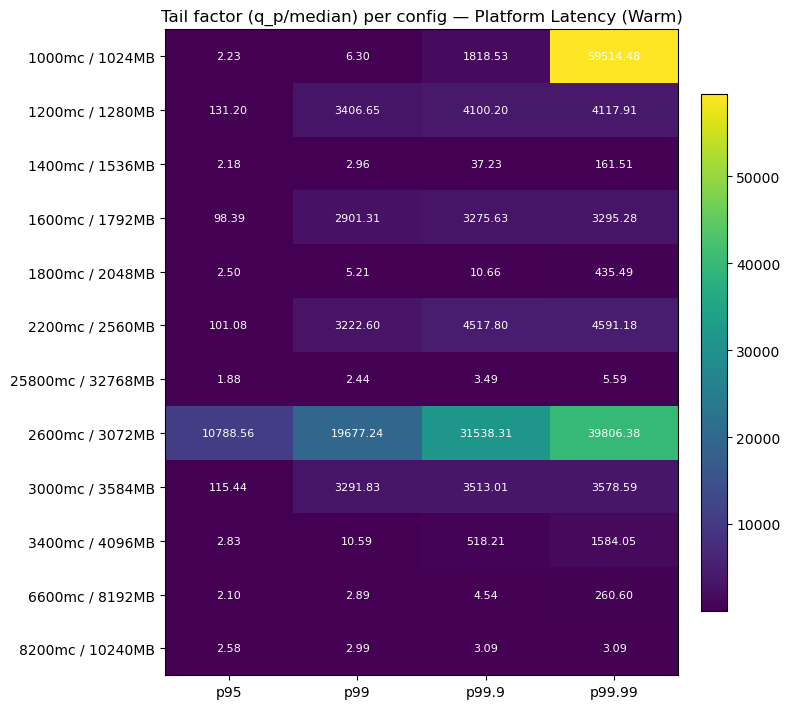

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb

con = duckdb.connect("huawei-data/2025-public-requests/2025-public-requests.duckdb")
TABLE = "requests_latency"

# Push string parsing, cold-start filtering, and percentiles down to DuckDB
query = f"""
WITH parsed AS (
    SELECT 
        podID,
        time_frontend,
        -- Subtract runtimeCost to isolate platform latency, convert to ms
        (totalCost_frontend - runtimeCost) * 1000 AS lat_ms,  
        split_part(podID, '-', 2) AS mc,
        split_part(podID, '-', 3) AS mem,
        ROW_NUMBER() OVER (PARTITION BY podID ORDER BY time_frontend ASC) as rn
    FROM {TABLE}
    WHERE totalCost_frontend IS NOT NULL
      AND runtimeCost IS NOT NULL
      AND time_frontend IS NOT NULL
),
warm_filtered AS (
    SELECT 
        lat_ms,
        mc || 'mc / ' || mem || 'MB' AS config
    FROM parsed
    WHERE rn > 1  -- Exclude cold starts (the first request per pod)
      AND regexp_matches(mc, '^\d+$')
      AND regexp_matches(mem, '^\d+$')
      AND lat_ms >= 0  -- Filter out negative anomalies due to clock/logging drift
)
SELECT 
    config,
    count(*) as n,
    quantile_cont(lat_ms, 0.5) AS median,
    quantile_cont(lat_ms, 0.95) AS p95,
    quantile_cont(lat_ms, 0.99) AS p99,
    quantile_cont(lat_ms, 0.999) AS p999,
    quantile_cont(lat_ms, 0.9999) AS p9999
FROM warm_filtered
GROUP BY config
ORDER BY config;
"""

aggregated_df = con.execute(query).df()
con.close()

percentiles = [95, 99, 99.9, 99.99]
col_map = {95: 'p95', 99: 'p99', 99.9: 'p999', 99.99: 'p9999'}
rows = []

for _, row in aggregated_df.iterrows():
    config = row["config"]
    n = row["n"]
    median = float(row["median"])
    
    if n < 2 or median <= 0:
        continue
        
    row_dict = {"config": config, "n": n, "median": median}
    
    for p in percentiles:
        t = row[col_map[p]]
        ratio = (t / median) if pd.notnull(t) else np.nan
        row_dict[f"p{p}_ratio"] = ratio
        
        n_tail_approx = int(n * (1 - (p / 100.0)))
        
        print(f"[{config}] p{p}: threshold={t:.6f}, q_p/median={ratio:.4f}, "
              f"approx >{p}%={n_tail_approx:,}")
              
    print(f"[{config}] Total warm values: {n:,}, Median: {median:.6f}\n")
    rows.append(row_dict)

out_df = pd.DataFrame(rows)
out_path = "../../data/tertiary_aggregations/warm_platform_latency_tail_factors.csv"
out_df.to_csv(out_path, index=False)
print(f"Saved: {out_path}")

if not rows:
    print("No configs with enough data — check SQL filters and podID format above.")
else:
    heat = np.array([[row[f"p{p}_ratio"] for p in percentiles] for row in rows])

    fig, ax = plt.subplots(figsize=(8, max(2, len(rows) * 0.6)))
    im = ax.imshow(heat, aspect="auto", cmap="viridis")
    
    ax.set_xticks(range(len(percentiles)))
    ax.set_xticklabels([f"p{p}" for p in percentiles])
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([row["config"] for row in rows])
    
    for i, row in enumerate(rows):
        for j, p in enumerate(percentiles):
            val = row[f"p{p}_ratio"]
            if np.isfinite(val):
                ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="white", fontsize=8)
                
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.title("Tail factor (q_p/median) per config — Platform Latency (Warm)") 
    plt.tight_layout()
    plt.show()

## Absolute platform latency per configuration

[1000mc / 1024MB] p95: threshold=2.33 ms, approx >95%=15,062,467
[1000mc / 1024MB] p99: threshold=6.57 ms, approx >99%=3,012,493
[1000mc / 1024MB] p99.9: threshold=1896.72 ms, approx >99.9%=301,249
[1000mc / 1024MB] p99.99: threshold=62073.60 ms, approx >99.99%=30,124
[1000mc / 1024MB] Total warm values: 301,249,341, Median: 1.04 ms

[1200mc / 1280MB] p95: threshold=287.13 ms, approx >95%=12
[1200mc / 1280MB] p99: threshold=7455.46 ms, approx >99%=2
[1200mc / 1280MB] p99.9: threshold=8973.28 ms, approx >99.9%=0
[1200mc / 1280MB] p99.99: threshold=9012.04 ms, approx >99.99%=0
[1200mc / 1280MB] Total warm values: 250, Median: 2.19 ms

[1400mc / 1536MB] p95: threshold=16.80 ms, approx >95%=1,127,672
[1400mc / 1536MB] p99: threshold=22.79 ms, approx >99%=225,534
[1400mc / 1536MB] p99.9: threshold=286.93 ms, approx >99.9%=22,553
[1400mc / 1536MB] p99.99: threshold=1243.51 ms, approx >99.99%=2,255
[1400mc / 1536MB] Total warm values: 22,553,453, Median: 7.71 ms

[1600mc / 1792MB] p95: thresh

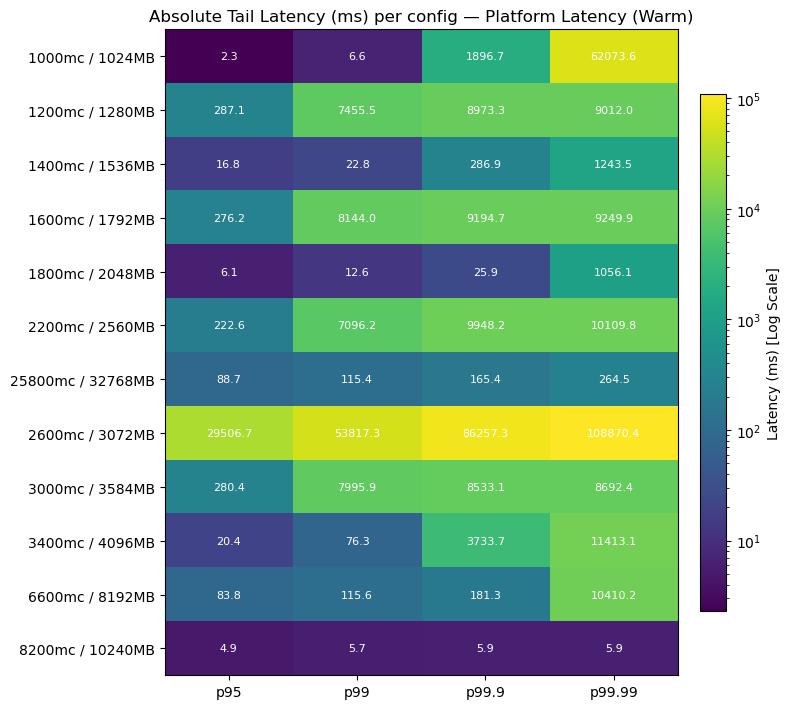

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from matplotlib.colors import LogNorm  # Required for log scale heatmap

con = duckdb.connect("huawei-data/2025-public-requests/2025-public-requests.duckdb")
TABLE = "requests_latency"

# Push string parsing, cold-start filtering, and percentiles down to DuckDB
query = f"""
WITH parsed AS (
    SELECT 
        podID,
        time_frontend,
        -- Subtract runtimeCost to isolate platform latency, convert to ms
        (totalCost_frontend - runtimeCost) * 1000 AS lat_ms,  
        split_part(podID, '-', 2) AS mc,
        split_part(podID, '-', 3) AS mem,
        ROW_NUMBER() OVER (PARTITION BY podID ORDER BY time_frontend ASC) as rn
    FROM {TABLE}
    WHERE totalCost_frontend IS NOT NULL
      AND runtimeCost IS NOT NULL
      AND time_frontend IS NOT NULL
),
warm_filtered AS (
    SELECT 
        lat_ms,
        mc || 'mc / ' || mem || 'MB' AS config
    FROM parsed
    WHERE rn > 1  -- Exclude cold starts (the first request per pod)
      AND regexp_matches(mc, '^\d+$')
      AND regexp_matches(mem, '^\d+$')
      AND lat_ms >= 0  -- Filter out negative anomalies due to clock/logging drift
)
SELECT 
    config,
    count(*) as n,
    quantile_cont(lat_ms, 0.5) AS median,
    quantile_cont(lat_ms, 0.95) AS p95,
    quantile_cont(lat_ms, 0.99) AS p99,
    quantile_cont(lat_ms, 0.999) AS p999,
    quantile_cont(lat_ms, 0.9999) AS p9999
FROM warm_filtered
GROUP BY config
ORDER BY config;
"""

aggregated_df = con.execute(query).df()
con.close()

percentiles = [95, 99, 99.9, 99.99]
col_map = {95: 'p95', 99: 'p99', 99.9: 'p999', 99.99: 'p9999'}
rows = []

for _, row in aggregated_df.iterrows():
    config = row["config"]
    n = row["n"]
    median = float(row["median"])
    
    if n < 2 or median <= 0:
        continue
        
    row_dict = {"config": config, "n": n, "median": median}
    
    for p in percentiles:
        t = row[col_map[p]]
        row_dict[f"p{p}_abs"] = t
        
        n_tail_approx = int(n * (1 - (p / 100.0)))
        
        print(f"[{config}] p{p}: threshold={t:.2f} ms, "
              f"approx >{p}%={n_tail_approx:,}")
              
    print(f"[{config}] Total warm values: {n:,}, Median: {median:.2f} ms\n")
    rows.append(row_dict)

out_df = pd.DataFrame(rows)
out_path = "../../data/tertiary_aggregations/warm_platform_latency_abs_values.csv"
out_df.to_csv(out_path, index=False)
print(f"Saved: {out_path}")

if not rows:
    print("No configs with enough data — check SQL filters and podID format above.")
else:
    heat = np.array([[row[f"p{p}_abs"] for p in percentiles] for row in rows])

    fig, ax = plt.subplots(figsize=(8, max(2, len(rows) * 0.6)))
    
    im = ax.imshow(heat, aspect="auto", cmap="viridis", norm=LogNorm())
    
    ax.set_xticks(range(len(percentiles)))
    ax.set_xticklabels([f"p{p}" for p in percentiles])
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([row["config"] for row in rows])
    
    for i, row in enumerate(rows):
        for j, p in enumerate(percentiles):
            val = row[f"p{p}_abs"]
            if np.isfinite(val):
                # We use .1f to keep numbers readable in the boxes
                ax.text(j, i, f"{val:.1f}", ha="center", va="center", color="white", fontsize=8)
                
    # Add a label to the colorbar to indicate unit and scale
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Latency (ms) [Log Scale]")
    plt.title("Absolute Tail Latency (ms) per config — Platform Latency (Warm)") 
    plt.tight_layout()
    plt.show()

## Absolute latencies with `workerCost` (comparison only)

`workerCost` is a sibling of `runtimeCost`, not its superset, so subtracting it leaves the function's execution time in the figure. Nothing in the paper uses this cell.

[1000mc / 1024MB] p95: threshold=32.96 ms, approx >95%=15,062,467
[1000mc / 1024MB] p99: threshold=243.46 ms, approx >99%=3,012,493
[1000mc / 1024MB] p99.9: threshold=5467.67 ms, approx >99.9%=301,249
[1000mc / 1024MB] p99.99: threshold=11439.84 ms, approx >99.99%=30,124
[1000mc / 1024MB] Total warm values: 301,249,342, Median: 1.19 ms

[1200mc / 1280MB] p95: threshold=287.92 ms, approx >95%=12
[1200mc / 1280MB] p99: threshold=7455.89 ms, approx >99%=2
[1200mc / 1280MB] p99.9: threshold=8973.60 ms, approx >99.9%=0
[1200mc / 1280MB] p99.99: threshold=9012.35 ms, approx >99.99%=0
[1200mc / 1280MB] Total warm values: 250, Median: 3.06 ms

[1400mc / 1536MB] p95: threshold=892.63 ms, approx >95%=1,127,672
[1400mc / 1536MB] p99: threshold=1288.84 ms, approx >99%=225,534
[1400mc / 1536MB] p99.9: threshold=1912.04 ms, approx >99.9%=22,553
[1400mc / 1536MB] p99.99: threshold=2939.72 ms, approx >99.99%=2,255
[1400mc / 1536MB] Total warm values: 22,553,453, Median: 208.69 ms

[1600mc / 1792MB] p9

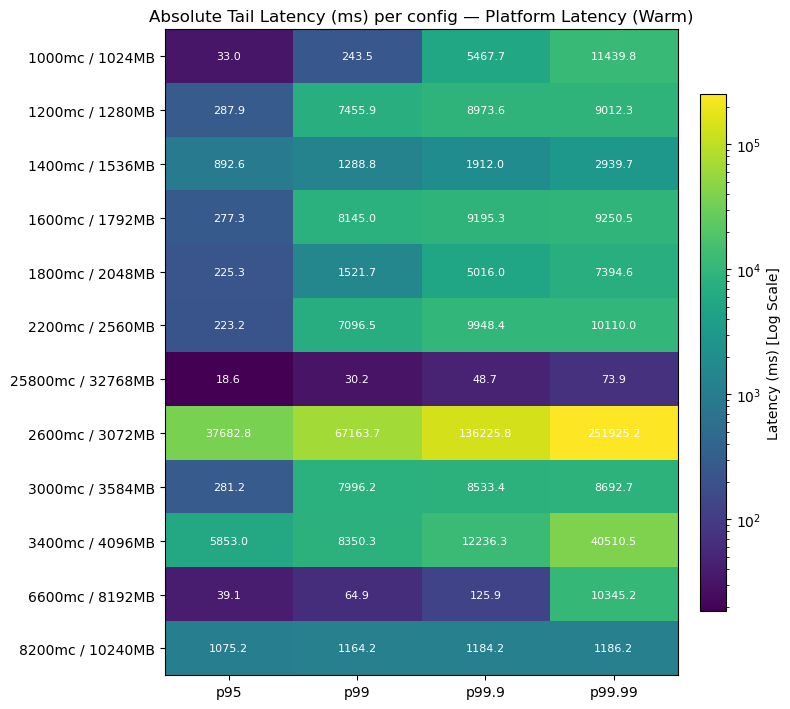

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from matplotlib.colors import LogNorm  # Required for log scale heatmap

con = duckdb.connect("huawei-data/2025-public-requests/2025-public-requests.duckdb")
TABLE = "requests_latency"

# Push string parsing, cold-start filtering, and percentiles down to DuckDB
query = f"""
WITH parsed AS (
    SELECT 
        podID,
        time_frontend,
        -- Subtract workerCost to isolate platform latency, convert to ms
        (totalCost_frontend - workerCost) * 1000 AS lat_ms,  
        split_part(podID, '-', 2) AS mc,
        split_part(podID, '-', 3) AS mem,
        ROW_NUMBER() OVER (PARTITION BY podID ORDER BY time_frontend ASC) as rn
    FROM {TABLE}
    WHERE totalCost_frontend IS NOT NULL
      AND runtimeCost IS NOT NULL
      AND time_frontend IS NOT NULL
),
warm_filtered AS (
    SELECT 
        lat_ms,
        mc || 'mc / ' || mem || 'MB' AS config
    FROM parsed
    WHERE rn > 1  -- Exclude cold starts (the first request per pod)
      AND regexp_matches(mc, '^\d+$')
      AND regexp_matches(mem, '^\d+$')
      AND lat_ms >= 0  -- Filter out negative anomalies due to clock/logging drift
)
SELECT 
    config,
    count(*) as n,
    quantile_cont(lat_ms, 0.5) AS median,
    quantile_cont(lat_ms, 0.95) AS p95,
    quantile_cont(lat_ms, 0.99) AS p99,
    quantile_cont(lat_ms, 0.999) AS p999,
    quantile_cont(lat_ms, 0.9999) AS p9999
FROM warm_filtered
GROUP BY config
ORDER BY config;
"""

aggregated_df = con.execute(query).df()
con.close()

percentiles = [95, 99, 99.9, 99.99]
col_map = {95: 'p95', 99: 'p99', 99.9: 'p999', 99.99: 'p9999'}
rows = []

for _, row in aggregated_df.iterrows():
    config = row["config"]
    n = row["n"]
    median = float(row["median"])
    
    if n < 2 or median <= 0:
        continue
        
    row_dict = {"config": config, "n": n, "median": median}
    
    for p in percentiles:
        t = row[col_map[p]]
        row_dict[f"p{p}_abs"] = t  # Store absolute ms values
        
        n_tail_approx = int(n * (1 - (p / 100.0)))
        
        print(f"[{config}] p{p}: threshold={t:.2f} ms, "
              f"approx >{p}%={n_tail_approx:,}")
              
    print(f"[{config}] Total warm values: {n:,}, Median: {median:.2f} ms\n")
    rows.append(row_dict)

out_df = pd.DataFrame(rows)
out_path = "../../data/tertiary_aggregations/warm_platform_latency_abs_values_workercost.csv"
out_df.to_csv(out_path, index=False)
print(f"Saved: {out_path}")

if not rows:
    print("No configs with enough data — check SQL filters and podID format above.")
else:
    heat = np.array([[row[f"p{p}_abs"] for p in percentiles] for row in rows])

    fig, ax = plt.subplots(figsize=(8, max(2, len(rows) * 0.6)))
    
    im = ax.imshow(heat, aspect="auto", cmap="viridis", norm=LogNorm())
    
    ax.set_xticks(range(len(percentiles)))
    ax.set_xticklabels([f"p{p}" for p in percentiles])
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([row["config"] for row in rows])
    
    for i, row in enumerate(rows):
        for j, p in enumerate(percentiles):
            val = row[f"p{p}_abs"]
            if np.isfinite(val):
                # .1f ensures the labels don't get too wide for the heatmap cells
                ax.text(j, i, f"{val:.1f}", ha="center", va="center", color="white", fontsize=8)
                
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Latency (ms) [Log Scale]")
    plt.title("Absolute Tail Latency (ms) per config — Platform Latency (Warm)") 
    plt.tight_layout()
    plt.show()

## Intraday percentiles

Writes `reconstruct_virtual_hour_latency.csv`, read by `overall_analysis.ipynb`. The trace has relative timestamps only, so hours are counted from the trace start. Values are `(pXX - p50) / p50`; the reader adds 1 to get TF.

In [ ]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = "huawei-data/2025-public-requests/2025-public-requests.duckdb"
TABLE = "requests_latency"

con = duckdb.connect(DB_PATH)

# 2. Push parsing, cold-start filtering, and percentile aggregations down to DuckDB
query = f"""
WITH parsed AS (
    SELECT 
        podID,
        time_frontend,
        (totalCost_frontend - runtimeCost) AS latency,
        ROW_NUMBER() OVER (PARTITION BY podID ORDER BY time_frontend ASC) as rn
    FROM {TABLE}
    WHERE totalCost_frontend IS NOT NULL 
      AND runtimeCost IS NOT NULL
      AND time_frontend IS NOT NULL
),
warm_filtered AS (
    SELECT 
        CAST(FLOOR(time_frontend / 3600) AS INTEGER) % 24 AS virtual_hour,
        latency
    FROM parsed
    WHERE rn > 1        -- Exclude cold starts (first request per pod)
      AND latency >= 0  -- Filter out negative anomalies due to clock drift
),
percentiles AS (
    SELECT 
        virtual_hour,
        quantile_cont(latency, 0.50) AS p50,
        quantile_cont(latency, 0.95) AS p95,
        quantile_cont(latency, 0.99) AS p99,
        quantile_cont(latency, 0.999) AS p999,
        quantile_cont(latency, 0.9999) AS p9999
    FROM warm_filtered
    GROUP BY virtual_hour
)
SELECT 
    virtual_hour,
    -- NULLIF prevents division by zero if median latency happens to be 0
    (p95 - p50) / NULLIF(p50, 0) AS rel_p95,
    (p99 - p50) / NULLIF(p50, 0) AS rel_p99,
    (p999 - p50) / NULLIF(p50, 0) AS rel_p999,
    (p9999 - p50) / NULLIF(p50, 0) AS rel_p9999
FROM percentiles
ORDER BY virtual_hour;
"""

# Fetch the aggregated 24 rows directly into a Pandas DataFrame
df = con.execute(query).df()
con.close()

# Export the minimal dataset to CSV
# This file will have exactly 24 rows and 5 columns
csv_filename = "../../data/tertiary_aggregations/reconstruct_virtual_hour_latency.csv"
df.to_csv(csv_filename, index=False)
print(f"Minimal data for figure reconstruction saved to: {csv_filename}")


plt.figure(figsize=(12, 6))

plt.plot(df['virtual_hour'], df['rel_p95'], label='p95', marker='o')
plt.plot(df['virtual_hour'], df['rel_p99'], label='p99', marker='s')
plt.plot(df['virtual_hour'], df['rel_p999'], label='p99.9', marker='^')
plt.plot(df['virtual_hour'], df['rel_p9999'], label='p99.99', marker='d')

plt.title('Relative Latency Increase Over Median by Virtual Hour (Warm Starts Only)')
plt.xlabel('Virtual Hour (0-23)')
plt.ylabel('Relative Increase (1.0 = +100% over median)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(title="Percentiles")
plt.tight_layout()

plt.show()

## Intraday percentiles per configuration (exploratory)

Minimal data for figure reconstruction saved to: reconstruct_hourly_latency_per_config.csv



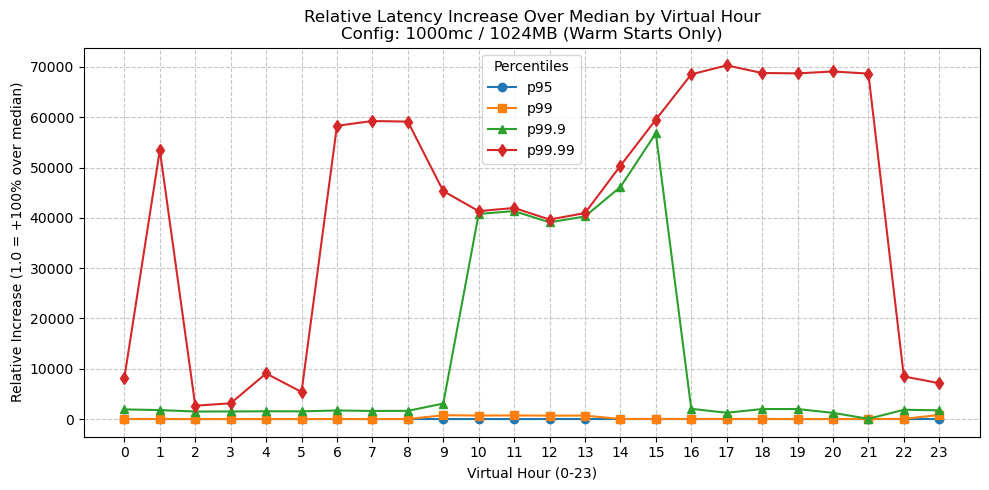

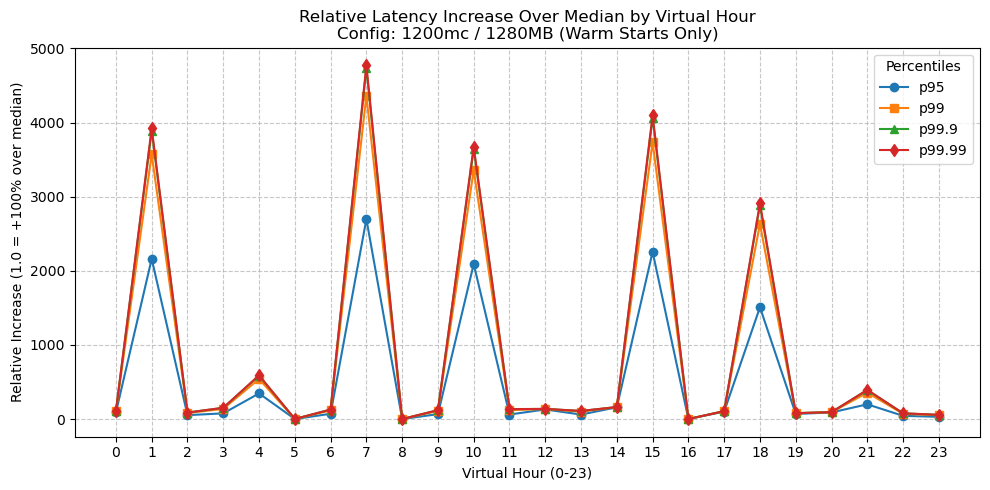

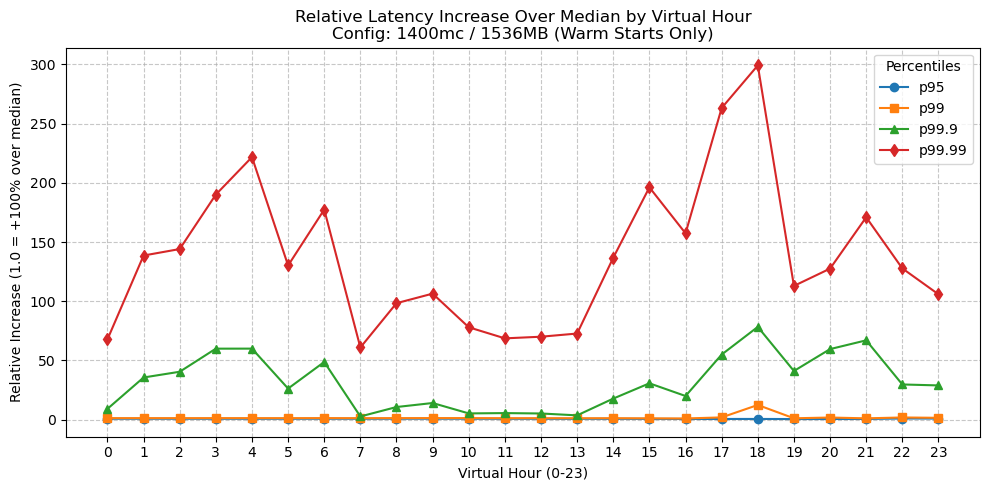

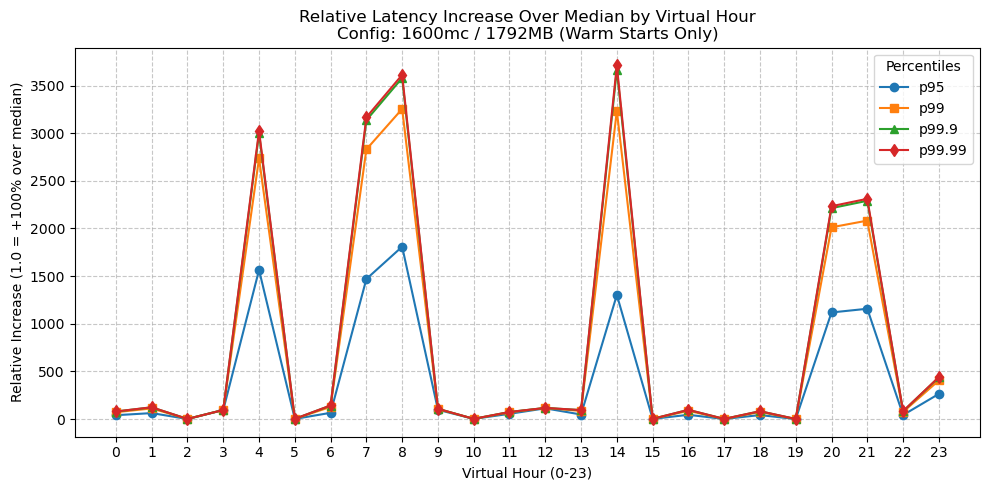

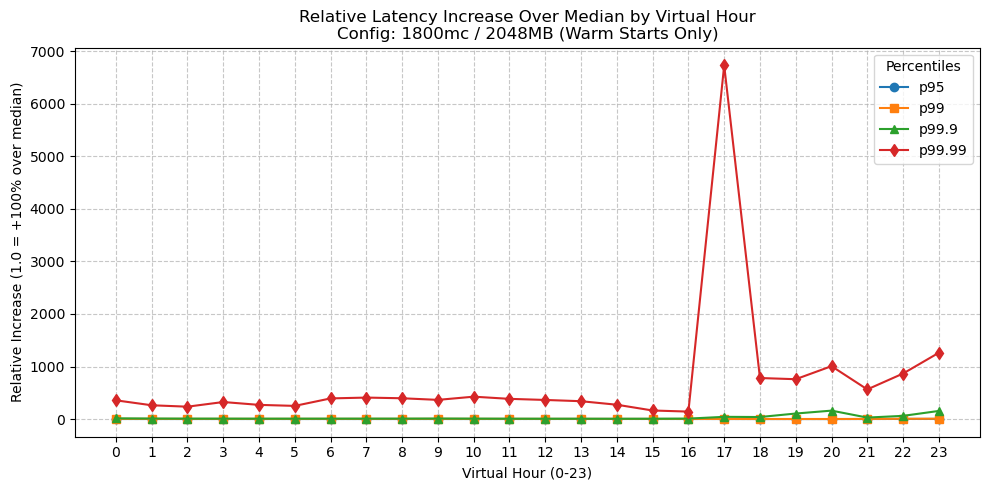

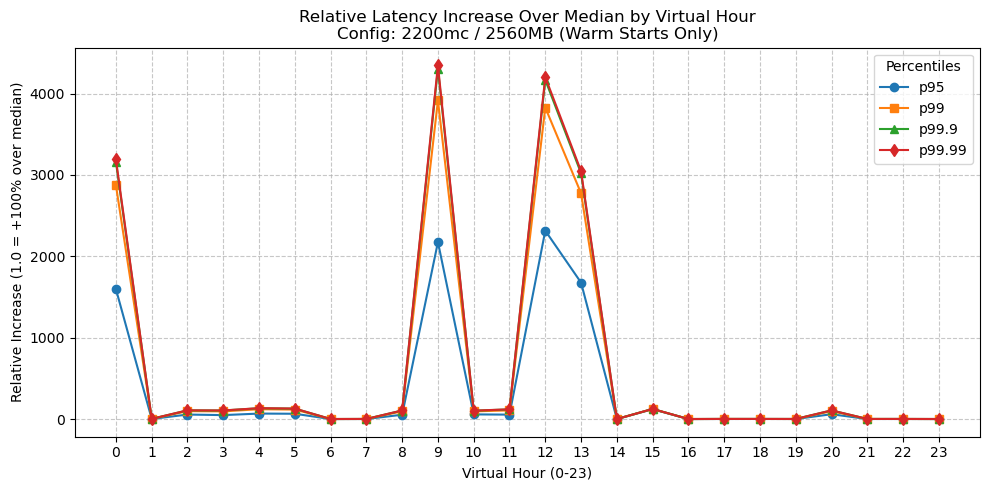

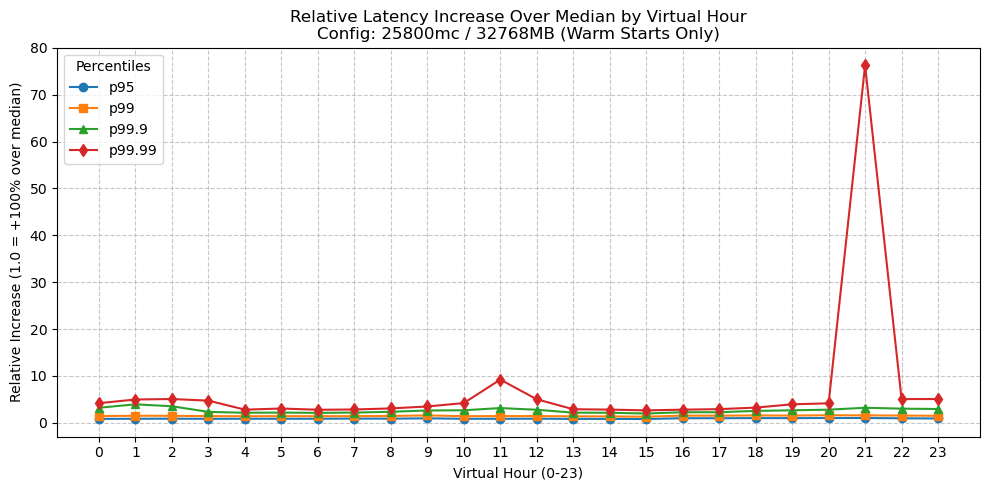

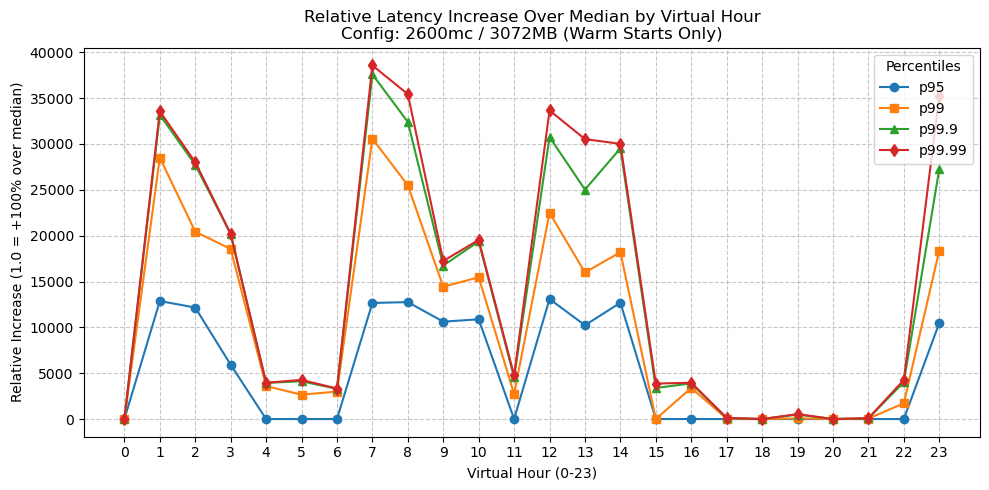

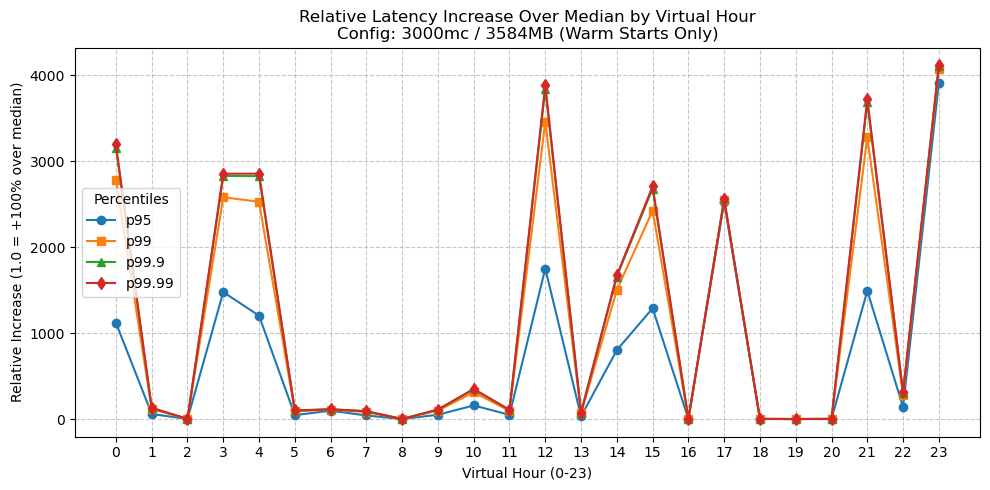

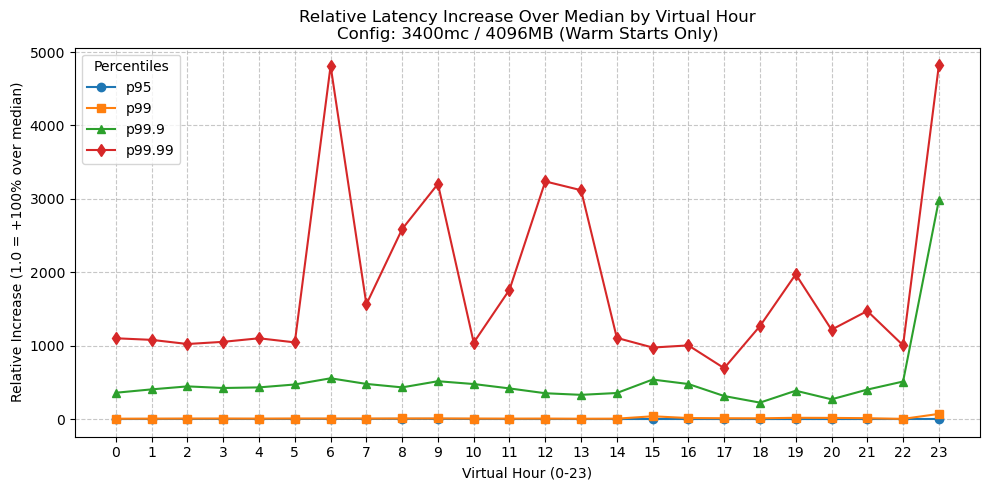

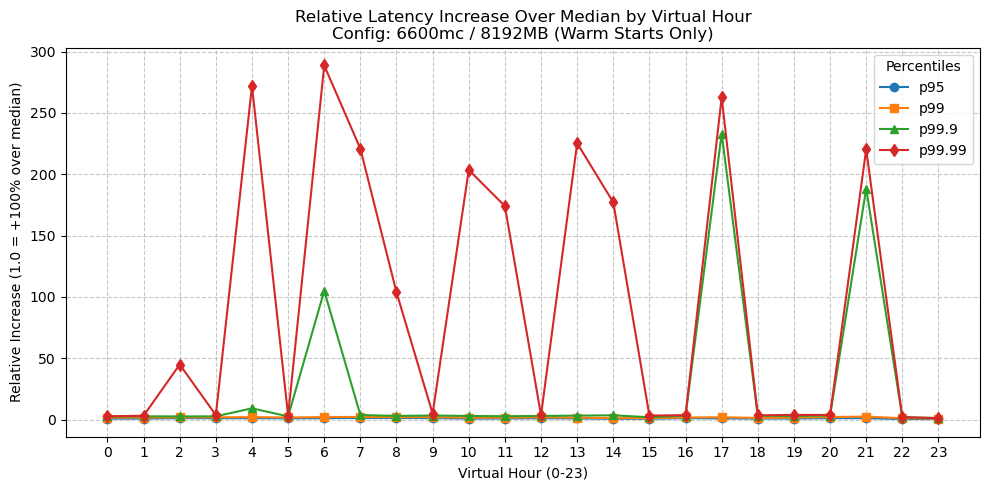

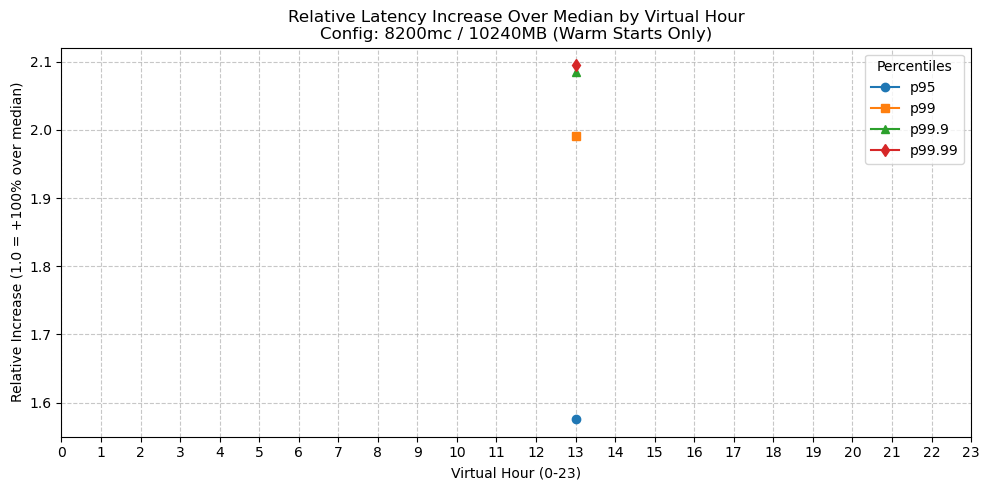

In [6]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = "huawei-data/2025-public-requests/2025-public-requests.duckdb"
TABLE = "requests_latency"

con = duckdb.connect(DB_PATH)

# 2. Push parsing, cold-start filtering, and percentile aggregations down to DuckDB
query = f"""
WITH parsed AS (
    SELECT 
        podID,
        time_frontend,
        (totalCost_frontend - runtimeCost) AS latency,
        split_part(podID, '-', 2) AS mc,
        split_part(podID, '-', 3) AS mem,
        ROW_NUMBER() OVER (PARTITION BY podID ORDER BY time_frontend ASC) as rn
    FROM {TABLE}
    WHERE totalCost_frontend IS NOT NULL 
      AND runtimeCost IS NOT NULL
      AND time_frontend IS NOT NULL
),
warm_filtered AS (
    SELECT 
        CAST(FLOOR(time_frontend / 3600) AS INTEGER) % 24 AS virtual_hour,
        mc || 'mc / ' || mem || 'MB' AS config,
        latency
    FROM parsed
    WHERE rn > 1        -- Exclude cold starts
      AND regexp_matches(mc, '^\d+$')
      AND regexp_matches(mem, '^\d+$')
      AND latency >= 0  -- Filter out negative anomalies due to clock drift
),
percentiles AS (
    SELECT 
        config,
        virtual_hour,
        quantile_cont(latency, 0.50) AS p50,
        quantile_cont(latency, 0.95) AS p95,
        quantile_cont(latency, 0.99) AS p99,
        quantile_cont(latency, 0.999) AS p999,
        quantile_cont(latency, 0.9999) AS p9999
    FROM warm_filtered
    GROUP BY config, virtual_hour
)
SELECT 
    config,
    virtual_hour,
    -- NULLIF prevents division by zero if median latency happens to be 0
    (p95 - p50) / NULLIF(p50, 0) AS rel_p95,
    (p99 - p50) / NULLIF(p50, 0) AS rel_p99,
    (p999 - p50) / NULLIF(p50, 0) AS rel_p999,
    (p9999 - p50) / NULLIF(p50, 0) AS rel_p9999
FROM percentiles
ORDER BY config, virtual_hour;
"""

# Fetch the aggregated data (24 rows per valid config) directly into a Pandas DataFrame
df = con.execute(query).df()
con.close()

# Export the minimal dataset needed to reconstruct all figures
csv_filename = "../../data/tertiary_aggregations/reconstruct_hourly_latency_per_config.csv"
df.to_csv(csv_filename, index=False)
print(f"Minimal data for figure reconstruction saved to: {csv_filename}\n")


# 3. Loop through configs and plot a separate figure for each
if df.empty:
    print("No configs with enough data — check SQL filters and podID format.")
else:
    unique_configs = df['config'].unique()
    
    for config in unique_configs:
        df_sub = df[df['config'] == config]
        
        plt.figure(figsize=(10, 5))
        
        plt.plot(df_sub['virtual_hour'], df_sub['rel_p95'], label='p95', marker='o')
        plt.plot(df_sub['virtual_hour'], df_sub['rel_p99'], label='p99', marker='s')
        plt.plot(df_sub['virtual_hour'], df_sub['rel_p999'], label='p99.9', marker='^')
        plt.plot(df_sub['virtual_hour'], df_sub['rel_p9999'], label='p99.99', marker='d')
        
        plt.title(f'Relative Latency Increase Over Median by Virtual Hour\nConfig: {config} (Warm Starts Only)')
        plt.xlabel('Virtual Hour (0-23)')
        plt.ylabel('Relative Increase (1.0 = +100% over median)')
        plt.xticks(range(0, 24))
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.legend(title="Percentiles")
        plt.tight_layout()
        
        plt.show()

## Cold factor (all calls / warm only), p80-p100

Writes `reconstruct_coldstart_platform_impact_percentiles.csv`. Sized for a large machine: adjust `threads` and `memory_limit`.

In [ ]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Paper-friendly styling (ACM Middleware 2-column format) ---
plt.rcParams.update({
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'font.family': 'serif',
})

DB_PATH = "huawei-data/2025-public-requests/2025-public-requests.duckdb"
TABLE = "requests_latency"

con = duckdb.connect(DB_PATH)

# Utilize all 30 cores
con.execute("PRAGMA threads=30;")
# Cap DuckDB at 250GB, leaving 50GB for Python/OS (prevents OOM)
con.execute("PRAGMA memory_limit='250GB';")
# Set a temp directory for safe disk-spilling (Point this to an NVMe drive if possible)
con.execute("PRAGMA temp_directory='./duckdb_temp';")

# 2. Generate the 500 percentile points (80th to 100th percentile)
percentile_grid_sql = np.linspace(0.8, 1.0, 500)
p_sql_list = "[" + ", ".join(f"{p:.6f}" for p in percentile_grid_sql) + "]"

# 3. Query DuckDB (Using EXACT quantiles)
query = f"""
WITH base AS (
    SELECT 
        (totalCost_frontend - runtimeCost) AS duration,
        ROW_NUMBER() OVER (PARTITION BY podID ORDER BY time_frontend ASC) as rn
    FROM {TABLE}
    WHERE totalCost_frontend IS NOT NULL
      AND runtimeCost IS NOT NULL
      AND time_frontend IS NOT NULL
      AND (totalCost_frontend - runtimeCost) >= 0
)
SELECT 
    quantile_cont(duration, {p_sql_list}) AS q_all,
    quantile_cont(CASE WHEN rn > 1 THEN duration END, {p_sql_list}) AS q_warm
FROM base;
"""

print("Calculating exact quantiles using 30 cores and up to 250GB RAM...")
result = con.execute(query).fetchone()
con.close()

# 4. Extract arrays and calculate the ratio safely
q_all = np.array(result[0], dtype=float)
q_warm = np.array(result[1], dtype=float)

# Avoid division by zero
with np.errstate(divide='ignore', invalid='ignore'):
    ratio = q_all / np.where(q_warm == 0, np.nan, q_warm)

percentile_grid_plot = np.linspace(80, 100, 500)

# 5. Export minimal dataset
out_df = pd.DataFrame({
    "percentile": percentile_grid_plot,
    "q_all_platform_duration": q_all,
    "q_warm_platform_duration": q_warm,
    "ratio_all_to_warm": ratio
})

csv_filename = "../../data/tertiary_aggregations/reconstruct_coldstart_platform_impact_percentiles.csv"
out_df.to_csv(csv_filename, index=False)
print(f"Minimal data for figure reconstruction saved to: {csv_filename}\n")

fig, ax = plt.subplots(figsize=(3.33, 2.25), dpi=300)

ax.plot(percentile_grid_plot, ratio, color='tab:blue', linewidth=1.4)

ax.set_xlabel("Percentile (%)")
ax.set_ylabel("Cold Factor (CF)")
ax.set_xlim(80, 100)
ax.set_ylim(1, 1.05)

ax.grid(True, linestyle="--", alpha=0.3, linewidth=0.6)

fig.tight_layout(pad=0.2)
plt.savefig("../../figures/tertiary/coldstart_platform_impact.pdf", bbox_inches="tight")
plt.show()